In [3]:
%pip install langgraph-supervisor

  Using cached langgraph_supervisor-0.0.31-py3-none-any.whl.metadata (14 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [67]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
load_dotenv()
os.environ['Tavily_API_KEY']='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'
os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
llm=init_chat_model("openai:gpt-4o")

In [68]:
from typing import Annotated
from langchain_community.tools.tavily_search import TavilySearchResults
tavily=TavilySearchResults(max_results=5)

In [69]:
from langchain_community.tools import tool
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.document_loaders import TextLoader
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter


In [70]:

from langchain_core.tools import Tool
def make_retriever_tool_from_text(file,name,desc):
    docs=TextLoader("Blog.txt",encoding='utf-8').load()
    chunks=RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=50).split_documents(docs)
    vectorstore=FAISS.from_documents(chunks,OpenAIEmbeddings())
    retriever=vectorstore.as_retriever()
    def tool_func(query:str):
        print(f'using tool:{name}')
        results=retriever.invoke(query)
        return"\n\n".join([doc.page_content for doc in results])
    return Tool(func=tool_func, name=name, description=desc)
internal_tool_1=make_retriever_tool_from_text("internal_docs.txt","InternalResearchNotes","Search internal research notes from the expermental results")

internal_tool_1

Tool(name='InternalResearchNotes', description='Search internal research notes from the expermental results', func=<function make_retriever_tool_from_text.<locals>.tool_func at 0x0000013A0FA42660>)

In [71]:
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.graph import MessagesState, END
from langgraph.types import Command


def get_next_node(last_message: BaseMessage, goto: str):
    if "final_answer" in str(last_message.content).lower():
        return END
    return goto

In [72]:
def make_system_prompt(suffix:str):
    return (
        "You are a helpful assistant collaborating with other agents to answer the user query."
        "use the provided tools to answer the user query."
        "If you are unable to answer fully thats okay, you can ask other agents for help."
        "will help where you left off,execute what you can make progress and pass the rest to the next agent."
        "If you or other agents agents are unable to answer the query fully, you can ask the user for more information."
        "Prefix your response with final_answer so the user knows you have completed your answer."
        f"\n{suffix}"
    )
         

C:\Users\anves\AppData\Local\Temp\ipykernel_17708\707012193.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


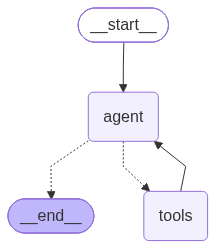

In [73]:
### Research Agent and Node
research_agent = create_react_agent(
    model=llm,
    tools=[tavily, internal_tool_1],
    prompt=make_system_prompt(
        "You can only use the tools provided to you to answer the user query. You can ask other agents for help if you are unable to answer the query fully."
    )
)
research_agent

In [ ]:
### Research Node
from typing import Literal


def research_node(state: MessagesState) -> Command[Literal["blog_generator", "END"]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content,
        name="researcher"
    )
    return Command(
        update={"messages": result["messages"]},
        goto=goto
    )

In [ ]:
### Blog writer Agent
blog_agent = create_react_agent(
    model=llm,
    tools=[tavily, internal_tool_1],
    prompt=make_system_prompt(
        "You are a blog writer and you can only use the tools provided to you to answer the query. You can ask other agents for help if you are unable to answer the query fully."
    )
)


def blog_node(state: MessagesState) -> Command[Literal["researcher", "END"]]:
    result = blog_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "researcher")
    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content,
        name="blog_generator"
    )
    return Command(
        update={"messages": result["messages"]},
        goto=goto
    )

C:\Users\anves\AppData\Local\Temp\ipykernel_17708\4013257358.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blog_agent = create_react_agent(


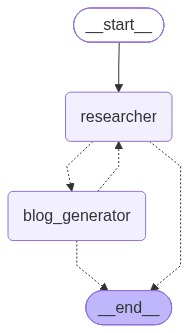

In [76]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(MessagesState)
workflow.add_node("researcher", research_node)
workflow.add_node("blog_generator", blog_node)
workflow.add_edge(START, "researcher")
graph = workflow.compile()
graph

In [77]:
response = graph.invoke({
    "messages": [HumanMessage(content="write a detailed blog on tesla")]
})

In [78]:
response["messages"][-1].content

"final_answerHere's a detailed blog on Tesla, incorporating recent developments and the company's impact on the electric vehicle market:\n\n---\n\n**Title: Unpacking the Journey of Tesla: A Glimpse into the Future of Electric Vehicles**\n\n*Introduction*\n\nWelcome to the electric revolution, spearheaded by none other than Tesla, Inc. Founded in 2003 by Martin Eberhard and Marc Tarpenning, Tesla has emerged as a powerful player in the automotive industry, challenging norms and propelling the movement towards sustainable energy. Under the leadership of Elon Musk, Tesla has become synonymous with innovation, speed, and cutting-edge technology.\n\n*Body*\n\n**1. The Evolution of Tesla**\n\nTesla started its journey with the Roadster, a breakthrough in electric vehicle technology. Over the years, the company expanded its lineup with models that shook the automotive market – the Model S, introducing unparalleled range and performance, followed by the more affordable Model 3, and then the sp